In [13]:
%pip install importlib_resources

In [14]:
# 1. Importando as bibliotecas modernas
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

import requests
from tensorflow.keras.preprocessing import image as keras_image

In [15]:
# Carregando o dataset cats_vs_dogs
(raw_train, raw_validation, raw_test), metadata = tfds.load(
    'cats_vs_dogs',
    split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'],
    with_info=True,
    as_supervised=True,
)

# Constantes de configuração
IMG_SIZE = 160
BATCH_SIZE = 32
SHUFFLE_BUFFER_SIZE = 1000

# Função de formatação da imagem
def format_example(image, label):
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1 # Normaliza para [-1, 1]
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return image, label

# Criando o pipeline otimizado (tf.data)
train_batches = raw_train.shuffle(SHUFFLE_BUFFER_SIZE).map(format_example).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
validation_batches = raw_validation.map(format_example).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_batches = raw_test.map(format_example).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Dados carregados e pipeline de pré-processamento pronto!")

Dados carregados e pipeline de pré-processamento pronto!


In [16]:
# Montagem do Modelo
IMG_SHAPE = (IMG_SIZE, IMG_SIZE, 3)

# Carregando a base do modelo (MobileNetV2)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               weights='imagenet')

# Congelando os pesos do modelo base
base_model.trainable = False

# Criando as novas camadas finais
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
prediction_layer = tf.keras.layers.Dense(1)

# Agrupando tudo no modelo sequencial
model = tf.keras.Sequential([
  base_model,
  global_average_layer,
  prediction_layer
])

# Compilando
model.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.0001),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

print("Arquitetura do modelo compilada com sucesso!")
model.summary()

Arquitetura do modelo compilada com sucesso!


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
# Treinamento
initial_epochs = 5
print("Iniciando o treinamento...")

history = model.fit(train_batches,
                    epochs=initial_epochs,
                    validation_data=validation_batches)

print("\nAvaliando no conjunto de testes...")
loss, accuracy = model.evaluate(test_batches)
print(f"Acurácia final no Teste: {accuracy * 100:.2f}%")

Iniciando o treinamento...
Epoch 1/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 62s 74ms/step - accuracy: 0.9145 - loss: 0.1999 - val_accuracy: 0.9673 - val_loss: 0.0923
Epoch 2/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 34s 57ms/step - accuracy: 0.9737 - loss: 0.0733 - val_accuracy: 0.9759 - val_loss: 0.0675
Epoch 3/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 41s 69ms/step - accuracy: 0.9789 - loss: 0.0586 - val_accuracy: 0.9798 - val_loss: 0.0595
Epoch 4/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 34s 55ms/step - accuracy: 0.9805 - loss: 0.0522 - val_accuracy: 0.9811 - val_loss: 0.0555
Epoch 5/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 33s 55ms/step - accuracy: 0.9816 - loss: 0.0487 - val_accuracy: 0.9824 - val_loss: 0.0530

Avaliando no conjunto de testes...
73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.9815 - loss: 0.0485
Acurácia final no Teste: 98.15%


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


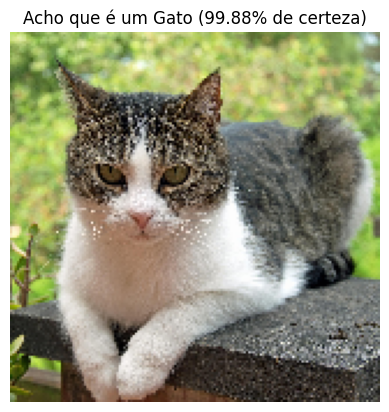

In [18]:
# Teste com imagens avulsas (URL da internet)

def testar_imagem_da_web(url_da_imagem):
    # Faz o download disfarçado de navegador de internet para evitar o Erro 403
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36'
    }

    try:
        resposta = requests.get(url_da_imagem, headers=headers)
        resposta.raise_for_status() # Verifica se o download foi bem sucedido

        with open("img_teste.jpg", "wb") as f:
            f.write(resposta.content)

    except Exception as e:
        print(f"Não foi possível baixar a imagem do link fornecido. Erro: {e}")
        return

    # Carrega a imagem no formato e tamanho correto
    img = keras_image.load_img("img_teste.jpg", target_size=(160, 160))

    # Converte para array
    img_array = keras_image.img_to_array(img)

    # Adiciona a dimensão do 'batch' (lote) - O modelo espera (batch, altura, largura, canais)
    img_batch = tf.expand_dims(img_array, 0)

    # Pré-processamento manual (igual ao tf.data)
    img_preprocessed = (img_batch / 127.5) - 1

    # Faz a previsão
    previsao = model.predict(img_preprocessed)

    # Aplica Sigmoid para transformar o "logit" bruto em uma probabilidade de 0 a 1
    score = tf.nn.sigmoid(previsao[0])

    # Exibe o resultado com a imagem
    plt.imshow(img)
    plt.axis('off')

    # 0 é Gato e 1 é Cachorro na base original
    if score < 0.5:
        resultado = "Gato"
        certeza = (1 - score.numpy()[0]) * 100
    else:
        resultado = "Cachorro"
        certeza = score.numpy()[0] * 100

    plt.title(f"Acho que é um {resultado} ({certeza:.2f}% de certeza)")
    plt.show()

url_teste = "https://cdn.pixabay.com/photo/2017/06/18/08/25/cat-2414828_1280.jpg"
testar_imagem_da_web(url_teste)